### Part 1 - Setup
**Q-Learning Tabular - CartPole-v1**


In [1]:
# ============================================================
# PART 1 - SETUP
# ============================================================

import numpy as np
import gymnasium as gym
import matplotlib.pyplot as plt

### Part 2 - Hyperparameters

In [2]:

# ============================================================
# PART 2 - HYPERPARAMETERS
# ============================================================

N_BINS = 6

ALPHA = 0.5
GAMMA = 0.99
EPSILON = 0.1

NUM_ACTIONS = 2

print("Intervals:", N_BINS)
print("Alpha:", ALPHA)
print("Gamma:", GAMMA)
print("Epsilon:", EPSILON)
print("Actions:", NUM_ACTIONS)


Intervals: 6
Alpha: 0.5
Gamma: 0.99
Epsilon: 0.1
Actions: 2


### Part 3 - Q-Table Initialization

In [3]:

# ============================================================
# PART 3 - Q-TABLE INITIALIZATION
# ============================================================

Q = np.zeros(
    (N_BINS, N_BINS, N_BINS, N_BINS, NUM_ACTIONS),
    dtype=float
)

print("Q-table shape:", Q.shape)
print("Total Q-values:", Q.size)

# Self-check
assert Q.shape == (6, 6, 6, 6, 2)
assert np.all(Q == 0)

# Example: check one discretized state
state = (3, 2, 3, 3)

print("State:", state)
print("Q-values:", Q[state])


Q-table shape: (6, 6, 6, 6, 2)
Total Q-values: 2592
State: (3, 2, 3, 3)
Q-values: [0. 0.]


### Part 4 - Epsilon-Greedy Policy

In [ ]:

# ============================================================
# PART 4 - EPSILON-GREEDY POLICY
# ============================================================

def epsilon_greedy(Q, state, epsilon, rng):

    # Exploration: choose a random action
    if rng.random() < epsilon:
        return int(rng.integers(NUM_ACTIONS))

    # Exploitation: choose an action with maximum Q-value
    q_values = Q[state]

    max_q = np.max(q_values)        # Encuentra el valor mas alto

    # Break ties randomly
    best_actions = np.flatnonzero(
        np.isclose(q_values, max_q)
    )

    return int(rng.choice(best_actions))


In [6]:

# ============================================================
# SELF-CHECK - EPSILON-GREEDY
# ============================================================

rng = np.random.default_rng(42)

state = (3, 2, 3, 3)

# Simulate previously learned Q-values
Q_test = Q.copy()

Q_test[state + (0,)] = 2.0
Q_test[state + (1,)] = 5.0

print("State:", state)
print("Q-values:", Q_test[state])

# With epsilon = 0, always exploit
action = epsilon_greedy(
    Q_test, state, epsilon=0.0, rng=rng
)

print("Selected action:", action)

assert action == 1
assert np.all(Q[state] == 0)

print("Self-check passed")


State: (3, 2, 3, 3)
Q-values: [2. 5.]
Selected action: 1
Self-check passed


### Part 5 - Q-Learning Update

In [7]:

# ============================================================
# PART 5 - Q-LEARNING UPDATE
# ============================================================

def update_q(Q, state, action, reward, next_state,
             terminated, alpha, gamma):

    current_q = Q[state + (action,)]

    if terminated:
        td_target = reward
    else:
        best_next_q = np.max(Q[next_state])
        td_target = reward + gamma * best_next_q

    td_error = td_target - current_q

    Q[state + (action,)] += alpha * td_error

    return td_error


In [8]:

# ============================================================
# SELF-CHECK - Q-LEARNING UPDATE
# ============================================================

Q_test = Q.copy()

state = (3, 2, 3, 3)
next_state = (3, 2, 4, 3)

action = 1
reward = 1.0

td_error = update_q(
    Q_test,
    state,
    action,
    reward,
    next_state,
    terminated=False,
    alpha=ALPHA,
    gamma=GAMMA
)

print("TD error:", td_error)
print("Updated Q-values:", Q_test[state])

assert np.isclose(Q_test[state + (1,)], 0.5)
assert np.isclose(Q_test[state + (0,)], 0.0)

print("Self-check passed")


TD error: 1.0
Updated Q-values: [0.  0.5]
Self-check passed


### Part 6 - Training

In [9]:

# ============================================================
# PART 6 - DISCRETIZATION
# ============================================================

MINIMOS = np.array([-2.4, -3.0, -0.2095, -3.5])
MAXIMOS = np.array([2.4, 3.0, 0.2095, 3.5])

def discretizar_estado(estado, n_bins):
    indices = []

    for i in range(4):
        limites = np.linspace(
            MINIMOS[i], MAXIMOS[i], n_bins + 1
        )

        indice = np.digitize(
            estado[i], limites[1:-1]
        )

        indices.append(int(indice))

    return tuple(indices)


In [10]:

# ============================================================
# PART 6 - Q-LEARNING TRAINING
# ============================================================

def train_q_learning(seed, n_bins=N_BINS, episodes=100,
                     alpha=ALPHA, gamma=GAMMA,
                     epsilon=EPSILON):

    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    rewards = []

    for episode in range(episodes):

        observation, info = env.reset(seed=seed + episode)
        state = discretizar_estado(observation, n_bins)

        total_reward = 0
        done = False

        while not done:

            action = epsilon_greedy(Q, state, epsilon, rng)

            next_observation, reward, terminated, truncated, info = env.step(action)

            next_state = discretizar_estado(
                next_observation, n_bins
            )

            update_q(
                Q, state, action, reward, next_state,
                terminated, alpha, gamma
            )

            state = next_state
            total_reward += reward

            done = terminated or truncated

        rewards.append(total_reward)

    env.close()

    return Q, rewards


In [11]:

# ============================================================
# SELF-CHECK - TRAINING
# ============================================================

Q_trained, rewards = train_q_learning(
    seed=42,
    n_bins=6,
    episodes=100
)

print("Q-table shape:", Q_trained.shape)
print("Episodes completed:", len(rewards))
print("First 10 rewards:", rewards[:10])
print("Last 10 rewards:", rewards[-10:])
print("Updated Q-values:", np.count_nonzero(Q_trained))

assert Q_trained.shape == (6, 6, 6, 6, 2)
assert len(rewards) == 100
assert np.count_nonzero(Q_trained) > 0

print("Self-check passed")


Q-table shape: (6, 6, 6, 6, 2)
Episodes completed: 100
First 10 rewards: [13.0, 8.0, 10.0, 11.0, 9.0, 10.0, 9.0, 12.0, 17.0, 9.0]
Last 10 rewards: [10.0, 24.0, 41.0, 15.0, 12.0, 11.0, 30.0, 18.0, 28.0, 11.0]
Updated Q-values: 100
Self-check passed


### Part 7 - Learning Curve

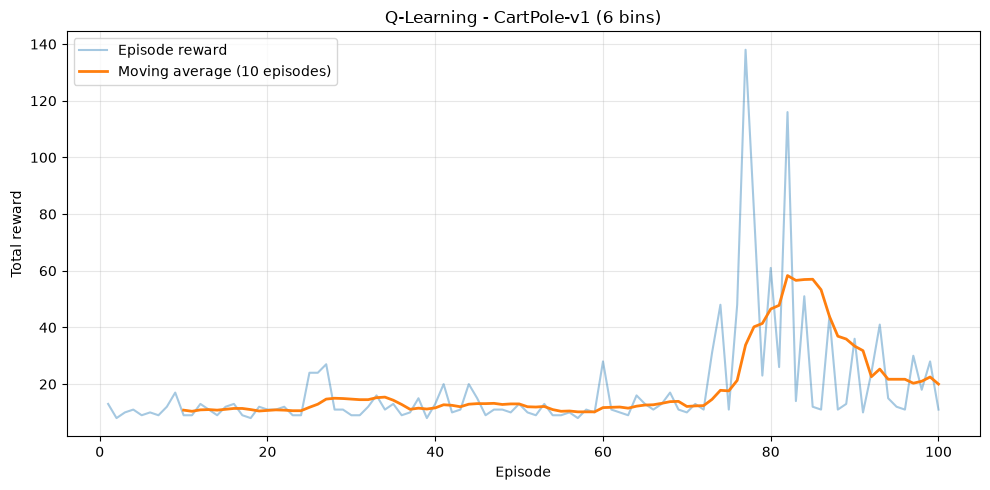

In [12]:

# ============================================================
# PART 7 - LEARNING CURVE
# ============================================================

# Episode numbers: 1, 2, 3, ..., 100
episodes = np.arange(1, len(rewards) + 1)

# Number of episodes used to calculate the moving average
window = 10

# Calculate the moving average of episode rewards
moving_avg = np.convolve(
    rewards,
    np.ones(window) / window,
    mode="valid"
)

# Episode numbers corresponding to the moving average
episodes_avg = episodes[window - 1:]

# Create the figure
plt.figure(figsize=(10, 5))

# Plot the reward obtained in each episode
plt.plot(
    episodes,
    rewards,
    label="Episode reward",
    alpha=0.4
)

# Plot the moving average
plt.plot(
    episodes_avg,
    moving_avg,
    label="Moving average (10 episodes)",
    linewidth=2
)

# Add title and labels
plt.title("Q-Learning - CartPole-v1 (6 bins)")
plt.xlabel("Episode")
plt.ylabel("Total reward")

# Show legend and grid
plt.legend()
plt.grid(True, alpha=0.3)

# Adjust layout and display
plt.tight_layout()
plt.show()


### Part 8 - Q-Learning Evaluation

In [13]:

# ============================================================
# PART 8 - Q-LEARNING EVALUATION
# ============================================================

def evaluate_q_learning(Q, n_bins, seed=100,
                        episodes=10):

    # Create the CartPole environment
    env = gym.make("CartPole-v1")

    # Random generator for reproducible tie-breaking
    rng = np.random.default_rng(seed)

    # Store the total reward from each evaluation episode
    evaluation_rewards = []

    # Run evaluation episodes
    for episode in range(episodes):

        # Reset the environment for a new episode
        observation, info = env.reset(seed=seed + episode)

        # Convert the initial observation into a discrete state
        state = discretizar_estado(observation, n_bins)

        total_reward = 0
        done = False

        while not done:

            # Choose the best known action (no exploration)
            action = epsilon_greedy(
                Q, state, epsilon=0.0, rng=rng
            )

            # Execute the selected action in CartPole
            next_observation, reward, terminated, truncated, info = env.step(action)

            # Convert the new observation into a discrete state
            state = discretizar_estado(
                next_observation, n_bins
            )

            # Accumulate the reward obtained
            total_reward += reward

            # Check whether the episode has finished
            done = terminated or truncated

        # Save the total reward for this episode
        evaluation_rewards.append(total_reward)

    # Close the environment
    env.close()

    # Calculate mean reward and standard deviation
    mean_reward = np.mean(evaluation_rewards)
    std_reward = np.std(evaluation_rewards)

    return evaluation_rewards, mean_reward, std_reward


In [14]:

# ============================================================
# SELF-CHECK - Q-LEARNING EVALUATION
# ============================================================

# Save the trained Q-table before evaluation
Q_before = Q_trained.copy()

# Evaluate the agent over 10 episodes
eval_rewards, mean_reward, std_reward = evaluate_q_learning(
    Q_trained,
    n_bins=6,
    seed=100,
    episodes=10
)

# Display evaluation results
print("Evaluation rewards:", eval_rewards)
print("Mean reward:", round(mean_reward, 2))
print("Standard deviation:", round(std_reward, 2))

# Verify that 10 episodes were evaluated
assert len(eval_rewards) == 10

# Verify that evaluation did not modify the Q-table
assert np.array_equal(Q_before, Q_trained)

print("Self-check passed")


Evaluation rewards: [10.0, 29.0, 10.0, 11.0, 10.0, 15.0, 13.0, 13.0, 13.0, 45.0]
Mean reward: 16.9
Standard deviation: 10.78
Self-check passed


### Part 9 - Training by Environment Steps

In [15]:

# ============================================================
# PART 9 - TRAINING BY ENVIRONMENT STEPS
# ============================================================

def train_q_learning_steps(seed, n_bins=N_BINS,
                           total_steps=1000,
                           alpha=ALPHA, gamma=GAMMA,
                           epsilon=EPSILON):

    # Create the random generator and CartPole environment
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    # Initialize a new Q-table for this training run
    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    # Store rewards and number of steps per completed episode
    rewards = []
    episode_steps = []

    # Count the total interactions with the environment
    steps = 0
    episode = 0

    # Train until reaching the requested step budget
    while steps < total_steps:

        # Start a new episode
        observation, info = env.reset(seed=seed + episode)
        state = discretizar_estado(observation, n_bins)

        total_reward = 0
        length = 0
        done = False

        # Continue until the episode ends or step budget is reached
        while not done and steps < total_steps:

            # Select an action using epsilon-greedy
            action = epsilon_greedy(Q, state, epsilon, rng)

            # Execute the action in CartPole
            next_observation, reward, terminated, truncated, info = env.step(action)

            # Discretize the next observation
            next_state = discretizar_estado(
                next_observation, n_bins
            )

            # Update the Q-value from this experience
            update_q(
                Q, state, action, reward, next_state,
                terminated, alpha, gamma
            )

            # Move to the next state
            state = next_state

            # Accumulate reward and count steps
            total_reward += reward
            length += 1
            steps += 1

            # Check whether CartPole ended the episode
            done = terminated or truncated

        # Save statistics only for completed episodes
        if done:
            rewards.append(total_reward)
            episode_steps.append(length)

        episode += 1

    # Close the environment
    env.close()

    return Q, rewards, episode_steps, steps


In [16]:

# ============================================================
# SELF-CHECK - TRAINING BY STEPS
# ============================================================

# Run a small training test with 1000 environment steps
Q_steps, rewards_steps, episode_steps, steps = train_q_learning_steps(
    seed=42,
    n_bins=6,
    total_steps=1000
)

# Display results
print("Q-table shape:", Q_steps.shape)
print("Total environment steps:", steps)
print("Completed episodes:", len(rewards_steps))
print("Updated Q-values:", np.count_nonzero(Q_steps))

# Verify the training step budget
assert steps == 1000

# Verify the Q-table dimensions
assert Q_steps.shape == (6, 6, 6, 6, 2)

# Verify that episode statistics match
assert len(rewards_steps) == len(episode_steps)

print("Self-check passed")


Q-table shape: (6, 6, 6, 6, 2)
Total environment steps: 1000
Completed episodes: 75
Updated Q-values: 65
Self-check passed


### Part 10 - Periodic Evaluation

In [17]:

# ============================================================
# PART 10 - TRAINING WITH PERIODIC EVALUATION
# ============================================================

def train_q_learning_eval(seed, n_bins=N_BINS,
                          total_steps=5000, eval_interval=1000,
                          alpha=ALPHA, gamma=GAMMA,
                          epsilon=EPSILON):

    # Create the random generator and CartPole environment
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    # Initialize a new Q-table
    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    # Store evaluation results
    eval_steps = []
    eval_means = []
    eval_stds = []

    # Count training steps and episodes
    steps = 0
    episode = 0

    # Train until reaching the step budget
    while steps < total_steps:

        # Reset CartPole at the beginning of each episode
        observation, info = env.reset(seed=seed + episode)
        state = discretizar_estado(observation, n_bins)

        done = False

        while not done and steps < total_steps:

            # Select an action using epsilon-greedy
            action = epsilon_greedy(Q, state, epsilon, rng)

            # Execute the action in CartPole
            next_observation, reward, terminated, truncated, info = env.step(action)

            # Discretize the next state
            next_state = discretizar_estado(next_observation, n_bins)

            # Update the Q-table using the experience
            update_q(
                Q, state, action, reward, next_state,
                terminated, alpha, gamma
            )

            # Continue from the next state
            state = next_state

            # Count only training steps
            steps += 1
            done = terminated or truncated

            # Evaluate when reaching the scheduled step
            if steps % eval_interval == 0:

                evaluation_rewards, mean_reward, std_reward = evaluate_q_learning(
                    Q,
                    n_bins=n_bins,
                    seed=1000,
                    episodes=10
                )

                # Save the results of this evaluation
                eval_steps.append(steps)
                eval_means.append(mean_reward)
                eval_stds.append(std_reward)

        episode += 1

    # Close the training environment
    env.close()

    return Q, eval_steps, eval_means, eval_stds, steps


In [18]:

# ============================================================
# SELF-CHECK - PERIODIC EVALUATION
# ============================================================

# Train for 5000 steps, evaluating every 1000 steps
Q_eval, eval_steps, eval_means, eval_stds, total_steps = train_q_learning_eval(
    seed=42,
    n_bins=6,
    total_steps=5000,
    eval_interval=1000
)

# Display evaluation results
print("Total training steps:", total_steps)
print("Evaluation steps:", eval_steps)
print("Mean rewards:", np.round(eval_means, 2))
print("Standard deviations:", np.round(eval_stds, 2))

# Verify the training budget
assert total_steps == 5000

# Verify that five evaluations were performed
assert eval_steps == [1000, 2000, 3000, 4000, 5000]

# Verify that each evaluation produced statistics
assert len(eval_means) == 5
assert len(eval_stds) == 5

print("Self-check passed")


Total training steps: 5000
Evaluation steps: [1000, 2000, 3000, 4000, 5000]
Mean rewards: [12.7 12.8 39.2 62.8 79.1]
Standard deviations: [ 4.24  4.19 38.8  39.22 69.03]
Self-check passed


### Part 10 - Complete Q-Learning Experiments

In [22]:

# ============================================================
# PART 10 - ENTRENAMIENTO EXPERIMENTAL
# ============================================================

import time

# Configuración de los experimentos
NIVELES = [6, 10, 20]
SEMILLAS = [42, 123, 456]

PASOS_ENTRENAMIENTO = 200_000
INTERVALO_EVALUACION = 10_000
EPISODIOS_EVALUACION = 10
EPISODIOS_FINALES = 100

def entrenar_experimento(seed, n_bins, total_steps):

    # Preparar el entorno, la semilla y una tabla Q nueva
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    # Guardar los resultados de las evaluaciones periódicas
    historial = []

    pasos = 0
    episodio = 0
    inicio = time.perf_counter()

    while pasos < total_steps:

        # Iniciar un episodio nuevo
        observacion, _ = env.reset(seed=seed + episodio)
        estado = discretizar_estado(observacion, n_bins)

        terminado = False

        while not terminado and pasos < total_steps:

            # Elegir acción mediante epsilon-greedy
            accion = epsilon_greedy(Q, estado, EPSILON, rng)

            # Realizar un paso y observar su consecuencia
            siguiente_obs, recompensa, terminated, truncated, _ = env.step(accion)

            siguiente_estado = discretizar_estado(
                siguiente_obs, n_bins
            )

            # Aprender de la experiencia obtenida
            update_q(
                Q, estado, accion, recompensa,
                siguiente_estado, terminated,
                ALPHA, GAMMA
            )

            # Actualizar estado y contador de pasos
            estado = siguiente_estado
            pasos += 1
            terminado = terminated or truncated

            # Evaluar sin exploración cada cierto número de pasos
            if pasos % INTERVALO_EVALUACION == 0:

                _, media, desviacion = evaluate_q_learning(
                    Q,
                    n_bins=n_bins,
                    seed=10000,
                    episodes=EPISODIOS_EVALUACION
                )

                historial.append({
                    "bins": n_bins,
                    "seed": seed,
                    "steps": pasos,
                    "mean_reward": float(media),
                    "std_reward": float(desviacion)
                })

        episodio += 1

    env.close()

    # Evaluación final con 100 episodios y sin exploración
    _, media_final, desviacion_final = evaluate_q_learning(
        Q,
        n_bins=n_bins,
        seed=20000,
        episodes=EPISODIOS_FINALES
    )

    duracion = time.perf_counter() - inicio

    resumen = {
        "bins": n_bins,
        "seed": seed,
        "training_steps": pasos,
        "episodes_started": episodio,
        "final_mean": float(media_final),
        "final_std": float(desviacion_final),
        "time_seconds": duracion
    }

    return Q, historial, resumen


In [23]:

# ============================================================
# PART 10 - EJECUCIÓN DE LOS EXPERIMENTOS
# ============================================================

todos_historiales = []
todos_resumenes = []

# Probar cada discretización con tres semillas diferentes
for n_bins in NIVELES:
    for seed in SEMILLAS:

        print(f"\nEntrenando: {n_bins} intervalos | semilla {seed}")

        Q_final, historial, resumen = entrenar_experimento(
            seed=seed,
            n_bins=n_bins,
            total_steps=PASOS_ENTRENAMIENTO
        )

        # Acumular resultados para las comparaciones
        todos_historiales.extend(historial)
        todos_resumenes.append(resumen)


        print(f"  Pasos: {resumen['training_steps']}")
        print(f"  Promedio final: {resumen['final_mean']:.2f}")
        print(f"  Desviación: {resumen['final_std']:.2f}")
        print(f"  Tiempo: {resumen['time_seconds']:.2f} segundos")


# Confirmar que finalizaron todos los entrenamientos
print("\nTodos los experimentos terminaron.")
print("Total de entrenamientos:", len(todos_resumenes))
print("Resultados disponibles en el notebook.")



Entrenando: 6 intervalos | semilla 42
  Pasos: 200000
  Promedio final: 294.71
  Desviación: 134.24
  Tiempo: 70.48 segundos

Entrenando: 6 intervalos | semilla 123
  Pasos: 200000
  Promedio final: 149.66
  Desviación: 56.27
  Tiempo: 85.43 segundos

Entrenando: 6 intervalos | semilla 456
  Pasos: 200000
  Promedio final: 144.48
  Desviación: 70.82
  Tiempo: 62.99 segundos

Entrenando: 10 intervalos | semilla 42
  Pasos: 200000
  Promedio final: 370.09
  Desviación: 135.43
  Tiempo: 71.05 segundos

Entrenando: 10 intervalos | semilla 123
  Pasos: 200000
  Promedio final: 162.90
  Desviación: 90.15
  Tiempo: 64.96 segundos

Entrenando: 10 intervalos | semilla 456
  Pasos: 200000
  Promedio final: 121.15
  Desviación: 40.74
  Tiempo: 61.27 segundos

Entrenando: 20 intervalos | semilla 42
  Pasos: 200000
  Promedio final: 74.72
  Desviación: 18.55
  Tiempo: 32.63 segundos

Entrenando: 20 intervalos | semilla 123
  Pasos: 200000
  Promedio final: 172.08
  Desviación: 54.40
  Tiempo: 25.7

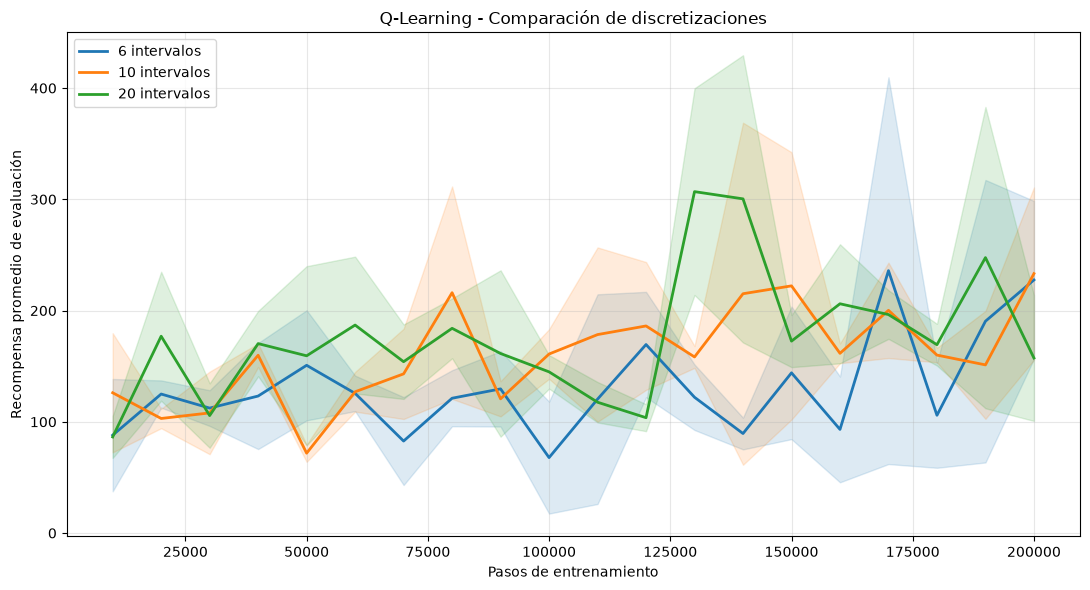


Discretización: 6 intervalos
Recompensa promedio: 196.28
Desviación entre semillas: 69.63
Tiempo promedio: 72.97 segundos

Discretización: 10 intervalos
Recompensa promedio: 218.05
Desviación entre semillas: 108.85
Tiempo promedio: 65.76 segundos

Discretización: 20 intervalos
Recompensa promedio: 145.93
Desviación entre semillas: 50.94
Tiempo promedio: 28.05 segundos


In [24]:

# ============================================================
# PART 10 - GRÁFICAS Y RESULTADOS COMPARATIVOS
# ============================================================

# Crear la figura para comparar las discretizaciones
plt.figure(figsize=(11, 6))

# Recorrer los niveles de discretización: 6, 10 y 20
for n_bins in NIVELES:

    # Obtener los pasos donde se realizaron evaluaciones
    pasos_eval = sorted({
        fila["steps"]
        for fila in todos_historiales
        if fila["bins"] == n_bins
    })

    medias = []
    desviaciones = []

    # Calcular el promedio de las tres semillas en cada evaluación
    for paso in pasos_eval:

        valores = [
            fila["mean_reward"]
            for fila in todos_historiales
            if fila["bins"] == n_bins
            and fila["steps"] == paso
        ]

        medias.append(np.mean(valores))

        # Calcular la variabilidad entre las semillas
        desviaciones.append(np.std(valores))

    medias = np.array(medias)
    desviaciones = np.array(desviaciones)

    # Dibujar la curva de recompensa promedio
    linea, = plt.plot(
        pasos_eval,
        medias,
        label=f"{n_bins} intervalos",
        linewidth=2
    )

    # Mostrar la variabilidad entre semillas con una zona sombreada
    plt.fill_between(
        pasos_eval,
        medias - desviaciones,
        medias + desviaciones,
        color=linea.get_color(),
        alpha=0.15
    )

# Configurar los elementos de la gráfica
plt.title("Q-Learning - Comparación de discretizaciones")
plt.xlabel("Pasos de entrenamiento")
plt.ylabel("Recompensa promedio de evaluación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar la gráfica directamente en el notebook
plt.show()


# ============================================================
# RESULTADOS FINALES POR DISCRETIZACIÓN
# ============================================================

for n_bins in NIVELES:

    # Seleccionar los resultados de las tres semillas
    resultados = [
        fila for fila in todos_resumenes
        if fila["bins"] == n_bins
    ]

    # Obtener las recompensas y los tiempos de entrenamiento
    recompensas = [
        fila["final_mean"] for fila in resultados
    ]

    tiempos = [
        fila["time_seconds"] for fila in resultados
    ]

    # Calcular las estadísticas finales
    recompensa_media = np.mean(recompensas)
    recompensa_std = np.std(recompensas)
    tiempo_medio = np.mean(tiempos)

    # Mostrar los resultados de cada discretización
    print(f"\nDiscretización: {n_bins} intervalos")
    print(f"Recompensa promedio: {recompensa_media:.2f}")
    print(f"Desviación entre semillas: {recompensa_std:.2f}")
    print(f"Tiempo promedio: {tiempo_medio:.2f} segundos")


### Part 11 - Epsilon Decay Experiment

In [28]:

# ============================================================
# PART 11 - ENTRENAMIENTO CON EPSILON DECRECIENTE
# ============================================================

def entrenar_epsilon_decay(seed, n_bins=10,
                            total_steps=200_000,
                            eval_interval=10_000,
                            alpha=ALPHA):

    # Preparar entorno, semilla y tabla Q
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    # Parámetros de exploración decreciente
    epsilon_inicio = 1.0
    epsilon_final = 0.05
    pasos_decay = 150_000

    historial = []
    pasos = 0
    episodio = 0
    inicio = time.perf_counter()

    # Primer paso donde se alcanza el umbral de evaluación
    paso_umbral = None

    while pasos < total_steps:

        # Reiniciar CartPole al comenzar cada episodio
        observacion, _ = env.reset(seed=seed + episodio)
        estado = discretizar_estado(observacion, n_bins)

        terminado = False

        while not terminado and pasos < total_steps:

            # Reducir epsilon gradualmente durante el entrenamiento
            progreso = min(pasos / pasos_decay, 1.0)

            epsilon = epsilon_inicio - (
                epsilon_inicio - epsilon_final
            ) * progreso

            # Seleccionar una acción con el epsilon actual
            accion = epsilon_greedy(Q, estado, epsilon, rng)

            # Ejecutar la acción y recibir la recompensa
            siguiente_obs, recompensa, terminated, truncated, _ = env.step(accion)

            siguiente_estado = discretizar_estado(
                siguiente_obs, n_bins
            )

            # Actualizar el valor Q de la acción realizada
            update_q(
                Q, estado, accion, recompensa,
                siguiente_estado, terminated,
                alpha, GAMMA
            )

            estado = siguiente_estado
            terminado = terminated or truncated
            pasos += 1

            # Evaluar cada 10.000 pasos, sin exploración
            if pasos % eval_interval == 0:

                _, media, desviacion = evaluate_q_learning(
                    Q,
                    n_bins=n_bins,
                    seed=10000,
                    episodes=10
                )

                historial.append({
                    "steps": pasos,
                    "mean_reward": float(media),
                    "std_reward": float(desviacion)
                })

                # Registrar la primera evaluación que alcanza 475
                if media >= 475 and paso_umbral is None:
                    paso_umbral = pasos

        episodio += 1

    env.close()

    # Evaluación final utilizando 100 episodios
    _, media_final, std_final = evaluate_q_learning(
        Q,
        n_bins=n_bins,
        seed=20000,
        episodes=100
    )

    tiempo = time.perf_counter() - inicio

    resumen = {
        "seed": seed,
        "bins": n_bins,
        "training_steps": pasos,
        "final_mean": float(media_final),
        "final_std": float(std_final),
        "first_threshold_step": paso_umbral,
        "time_seconds": tiempo
    }

    return Q, historial, resumen



Semilla: 42
Recompensa final: 221.91
Desviación: 100.45
Tiempo: 38.53 s
Primer paso >= 475: 100000

Semilla: 123
Recompensa final: 181.50
Desviación: 94.26
Tiempo: 329.40 s
Primer paso >= 475: None

Semilla: 456
Recompensa final: 234.63
Desviación: 135.94
Tiempo: 24.43 s
Primer paso >= 475: None


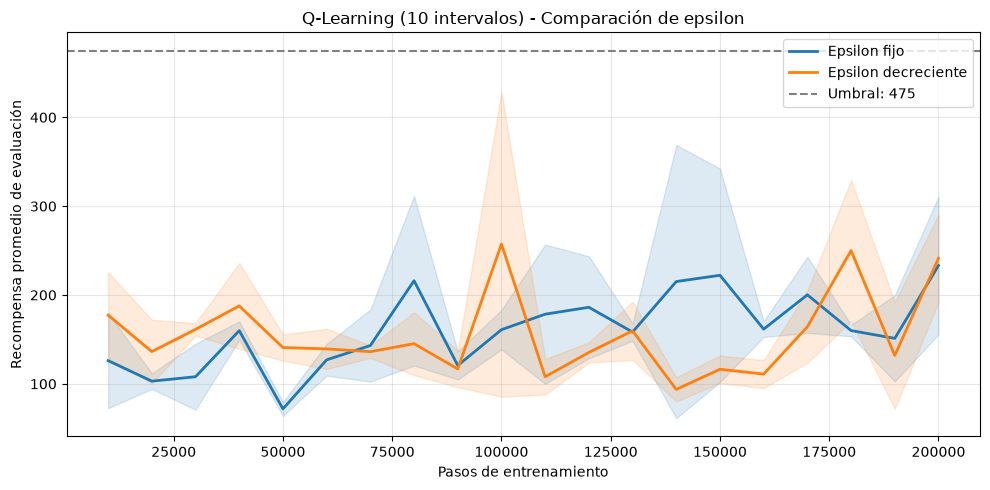


Epsilon fijo:
Media final: 218.05
Desviación entre semillas: 108.85

Epsilon decreciente:
Media final: 212.68
Desviación entre semillas: 22.65


In [26]:

# ============================================================
# PART 11 - COMPARACIÓN DE EPSILON FIJO Y DECRECIENTE
# ============================================================

resultados_decay = []
historiales_decay = []

# Ejecutar el experimento con las mismas tres semillas
for seed in SEMILLAS:

    Q_decay, historial, resumen = entrenar_epsilon_decay(
        seed=seed,
        n_bins=10,
        total_steps=PASOS_ENTRENAMIENTO,
        eval_interval=INTERVALO_EVALUACION
    )

    resultados_decay.append(resumen)

    # Asociar cada evaluación con su semilla
    for fila in historial:
        historiales_decay.append({
            **fila,
            "seed": seed
        })

    print(f"\nSemilla: {seed}")
    print(f"Recompensa final: {resumen['final_mean']:.2f}")
    print(f"Desviación: {resumen['final_std']:.2f}")
    print(f"Tiempo: {resumen['time_seconds']:.2f} s")
    print(f"Primer paso >= 475: {resumen['first_threshold_step']}")


# ============================================================
# CURVAS DE EVALUACIÓN
# ============================================================

plt.figure(figsize=(10, 5))

# Comparar usando los pasos de evaluación
pasos_eval = list(range(
    INTERVALO_EVALUACION,
    PASOS_ENTRENAMIENTO + 1,
    INTERVALO_EVALUACION
))

for nombre, datos in [
    ("Epsilon fijo", [
        fila for fila in todos_historiales
        if fila["bins"] == 10
    ]),
    ("Epsilon decreciente", historiales_decay)
]:

    medias = []
    desviaciones = []

    for paso in pasos_eval:

        valores = [
            fila["mean_reward"]
            for fila in datos
            if fila["steps"] == paso
        ]

        medias.append(np.mean(valores))
        desviaciones.append(np.std(valores))

    medias = np.array(medias)
    desviaciones = np.array(desviaciones)

    linea, = plt.plot(
        pasos_eval, medias,
        label=nombre,
        linewidth=2
    )

    # Variación de los resultados entre semillas
    plt.fill_between(
        pasos_eval,
        medias - desviaciones,
        medias + desviaciones,
        color=linea.get_color(),
        alpha=0.15
    )

plt.axhline(
    y=475,
    linestyle="--",
    color="gray",
    label="Umbral: 475"
)

plt.title("Q-Learning (10 intervalos) - Comparación de epsilon")
plt.xlabel("Pasos de entrenamiento")
plt.ylabel("Recompensa promedio de evaluación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# ============================================================
# COMPARACIÓN FINAL
# ============================================================

base = [
    fila["final_mean"]
    for fila in todos_resumenes
    if fila["bins"] == 10
]

decay = [
    fila["final_mean"]
    for fila in resultados_decay
]

print("\nEpsilon fijo:")
print(f"Media final: {np.mean(base):.2f}")
print(f"Desviación entre semillas: {np.std(base):.2f}")

print("\nEpsilon decreciente:")
print(f"Media final: {np.mean(decay):.2f}")
print(f"Desviación entre semillas: {np.std(decay):.2f}")


### Part 12 - Alpha Comparison

In [29]:

# ============================================================
# COMPARACIÓN DE ALPHA - NUEVOS ENTRENAMIENTOS
# ============================================================

# Conservar los resultados anteriores de alpha = 0.5
resultados_alpha = {0.5: resultados_decay}
historiales_alpha = {0.5: historiales_decay}

# Probar únicamente los valores que faltan
for alpha in [0.1, 0.3]:

    resultados = []
    historiales = []

    for seed in SEMILLAS:

        # Entrenar con el alpha y la semilla seleccionados
        Q_alpha, historial, resumen = entrenar_epsilon_decay(
            seed=seed,
            n_bins=10,
            total_steps=PASOS_ENTRENAMIENTO,
            eval_interval=INTERVALO_EVALUACION,
            alpha=alpha
        )

        # Guardar los resultados en memoria
        resultados.append(resumen)

        for fila in historial:
            historiales.append({
                **fila,
                "seed": seed
            })

        # Mostrar las métricas de cada ejecución
        print(
            f"Alpha: {alpha} | Semilla: {seed} | "
            f"Recompensa: {resumen['final_mean']:.2f} | "
            f"Tiempo: {resumen['time_seconds']:.2f} s"
        )

    resultados_alpha[alpha] = resultados
    historiales_alpha[alpha] = historiales

# Mostrar la comparación final
for alpha in [0.1, 0.3, 0.5]:

    recompensas = [
        fila["final_mean"]
        for fila in resultados_alpha[alpha]
    ]

    print(f"\nAlpha = {alpha}")
    print(f"Recompensa promedio: {np.mean(recompensas):.2f}")
    print(f"Desviación entre semillas: {np.std(recompensas):.2f}")


Alpha: 0.1 | Semilla: 42 | Recompensa: 483.21 | Tiempo: 26.88 s
Alpha: 0.1 | Semilla: 123 | Recompensa: 178.11 | Tiempo: 21.60 s
Alpha: 0.1 | Semilla: 456 | Recompensa: 229.99 | Tiempo: 22.97 s
Alpha: 0.3 | Semilla: 42 | Recompensa: 332.32 | Tiempo: 22.76 s
Alpha: 0.3 | Semilla: 123 | Recompensa: 304.10 | Tiempo: 23.10 s
Alpha: 0.3 | Semilla: 456 | Recompensa: 186.78 | Tiempo: 34.36 s

Alpha = 0.1
Recompensa promedio: 297.10
Desviación entre semillas: 133.29

Alpha = 0.3
Recompensa promedio: 274.40
Desviación entre semillas: 63.02

Alpha = 0.5
Recompensa promedio: 212.68
Desviación entre semillas: 22.65


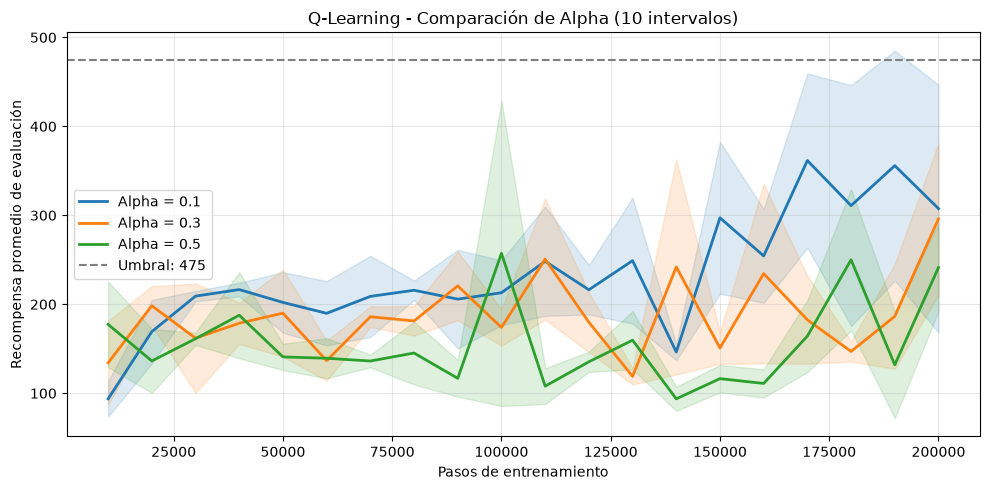

In [30]:
# ============================================================
# CURVAS DE APRENDIZAJE - COMPARACIÓN DE ALPHA
# ============================================================

plt.figure(figsize=(10, 5))

# Comparar los tres valores de alpha
for alpha in [0.1, 0.3, 0.5]:

    datos = historiales_alpha[alpha]

    # Obtener los pasos donde se evaluó al agente
    pasos_eval = sorted({
        fila["steps"] for fila in datos
    })

    medias = []
    desviaciones = []

    # Calcular el promedio y la variación entre semillas
    for paso in pasos_eval:

        valores = [
            fila["mean_reward"]
            for fila in datos
            if fila["steps"] == paso
        ]

        medias.append(np.mean(valores))
        desviaciones.append(np.std(valores))

    medias = np.array(medias)
    desviaciones = np.array(desviaciones)

    # Dibujar la curva promedio
    linea, = plt.plot(
        pasos_eval,
        medias,
        label=f"Alpha = {alpha}",
        linewidth=2
    )

    # Mostrar la desviación entre las tres semillas
    plt.fill_between(
        pasos_eval,
        medias - desviaciones,
        medias + desviaciones,
        color=linea.get_color(),
        alpha=0.15
    )

# Mostrar el umbral del proyecto
plt.axhline(
    475,
    linestyle="--",
    color="gray",
    label="Umbral: 475"
)

plt.title("Q-Learning - Comparación de Alpha (10 intervalos)")
plt.xlabel("Pasos de entrenamiento")
plt.ylabel("Recompensa promedio de evaluación")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Part 13 - Discretization Limits Comparison

In [31]:

# ============================================================
# PART 13 - COMPARACIÓN DE LÍMITES DE DISCRETIZACIÓN
# ============================================================

# Conservar los límites originales
minimos_originales = MINIMOS.copy()
maximos_originales = MAXIMOS.copy()

# Configuraciones que vamos a comparar
configuraciones_limites = {
    "Ajuste A": {
        "minimos": [-2.4, -2.0, -0.2095, -2.5],
        "maximos": [2.4, 2.0, 0.2095, 2.5]
    },
    "Ajuste B": {
        "minimos": [-2.4, -1.5, -0.2095, -2.0],
        "maximos": [2.4, 1.5, 0.2095, 2.0]
    }
}

# Recuperar los resultados anteriores con alpha = 0.1
resultados_limites = {
    "Original": resultados_alpha[0.1]
}

historiales_limites = {
    "Original": historiales_alpha[0.1]
}

# Ejecutar solamente las configuraciones nuevas
try:
    for nombre, limites in configuraciones_limites.items():

        # Cambiar únicamente los límites de discretización
        MINIMOS = np.array(limites["minimos"])
        MAXIMOS = np.array(limites["maximos"])

        resultados = []
        historiales = []

        for seed in SEMILLAS:

            # Entrenar con alpha = 0.1 y epsilon decreciente
            Q_limites, historial, resumen = entrenar_epsilon_decay(
                seed=seed,
                n_bins=10,
                total_steps=PASOS_ENTRENAMIENTO,
                eval_interval=INTERVALO_EVALUACION,
                alpha=0.1
            )

            # Conservar el resultado de cada semilla
            resultados.append(resumen)

            for fila in historial:
                historiales.append({
                    **fila,
                    "seed": seed
                })

            print(
                f"{nombre} | Semilla: {seed} | "
                f"Recompensa: {resumen['final_mean']:.2f} | "
                f"Tiempo: {resumen['time_seconds']:.2f} s"
            )

        resultados_limites[nombre] = resultados
        historiales_limites[nombre] = historiales

finally:
    # Restaurar los límites originales
    MINIMOS = minimos_originales.copy()
    MAXIMOS = maximos_originales.copy()


# ============================================================
# COMPARACIÓN FINAL DE RESULTADOS
# ============================================================

for nombre, resultados in resultados_limites.items():

    recompensas = [
        fila["final_mean"]
        for fila in resultados
    ]

    print(f"\nConfiguración: {nombre}")
    print(f"Recompensas por semilla: {np.round(recompensas, 2)}")
    print(f"Promedio final: {np.mean(recompensas):.2f}")
    print(f"Desviación entre semillas: {np.std(recompensas):.2f}")
    print(f"Semillas con recompensa >= 475: {np.sum(np.array(recompensas) >= 475)}/3")


Ajuste A | Semilla: 42 | Recompensa: 500.00 | Tiempo: 50.34 s
Ajuste A | Semilla: 123 | Recompensa: 198.38 | Tiempo: 37.10 s
Ajuste A | Semilla: 456 | Recompensa: 486.23 | Tiempo: 39.04 s
Ajuste B | Semilla: 42 | Recompensa: 479.46 | Tiempo: 42.65 s
Ajuste B | Semilla: 123 | Recompensa: 242.77 | Tiempo: 28.62 s
Ajuste B | Semilla: 456 | Recompensa: 342.42 | Tiempo: 30.12 s

Configuración: Original
Recompensas por semilla: [483.21 178.11 229.99]
Promedio final: 297.10
Desviación entre semillas: 133.29
Semillas con recompensa >= 475: 1/3

Configuración: Ajuste A
Recompensas por semilla: [500.   198.38 486.23]
Promedio final: 394.87
Desviación entre semillas: 139.05
Semillas con recompensa >= 475: 2/3

Configuración: Ajuste B
Recompensas por semilla: [479.46 242.77 342.42]
Promedio final: 354.88
Desviación entre semillas: 97.03
Semillas con recompensa >= 475: 1/3


### Part 14 - Training Budget Comparison

In [32]:

# ============================================================
# PART 14 - ENTRENAMIENTO CON PRESUPUESTO AMPLIADO
# ============================================================

def entrenar_presupuesto(seed, n_bins=10, alpha=0.1,
                         total_steps=400_000):

    # Crear el entorno y una tabla Q nueva
    rng = np.random.default_rng(seed)
    env = gym.make("CartPole-v1")

    Q = np.zeros(
        (n_bins, n_bins, n_bins, n_bins, NUM_ACTIONS),
        dtype=float
    )

    # Configurar la exploración decreciente
    epsilon_inicio = 1.0
    epsilon_final = 0.05
    pasos_decay = 150_000

    # Puntos donde evaluaremos el rendimiento
    puntos_evaluacion = [200_000, 300_000, 400_000]

    historial = []
    pasos = 0
    episodio = 0
    inicio = time.perf_counter()

    try:
        while pasos < total_steps:

            # Reiniciar el entorno para un episodio nuevo
            observacion, _ = env.reset(seed=seed + episodio)
            estado = discretizar_estado(observacion, n_bins)

            terminado = False

            while not terminado and pasos < total_steps:

                # Calcular epsilon según los pasos realizados
                progreso = min(pasos / pasos_decay, 1.0)

                epsilon = epsilon_inicio - (
                    epsilon_inicio - epsilon_final
                ) * progreso

                # Seleccionar una acción
                accion = epsilon_greedy(
                    Q, estado, epsilon, rng
                )

                # Ejecutar la acción en CartPole
                siguiente_obs, recompensa, terminated, truncated, _ = env.step(
                    accion
                )

                siguiente_estado = discretizar_estado(
                    siguiente_obs, n_bins
                )

                # Actualizar la tabla Q
                update_q(
                    Q, estado, accion, recompensa,
                    siguiente_estado, terminated,
                    alpha, GAMMA
                )

                estado = siguiente_estado
                terminado = terminated or truncated
                pasos += 1

                # Evaluar con 100 episodios en los puntos definidos
                if pasos in puntos_evaluacion:

                    _, media, desviacion = evaluate_q_learning(
                        Q,
                        n_bins=n_bins,
                        seed=20000,
                        episodes=100
                    )

                    historial.append({
                        "seed": seed,
                        "steps": pasos,
                        "mean_reward": float(media),
                        "std_reward": float(desviacion),
                        "time_seconds": time.perf_counter() - inicio
                    })

            episodio += 1

    finally:
        env.close()

    return historial


# ============================================================
# EJECUCIÓN CON AJUSTE A
# ============================================================

# Mantener una copia de los límites anteriores
minimos_anteriores = MINIMOS.copy()
maximos_anteriores = MAXIMOS.copy()

resultados_presupuesto = []

try:
    # Utilizar los límites del Ajuste A
    MINIMOS = np.array([-2.4, -2.0, -0.2095, -2.5])
    MAXIMOS = np.array([2.4, 2.0, 0.2095, 2.5])

    # Entrenar las tres semillas de manera independiente
    for seed in SEMILLAS:

        historial = entrenar_presupuesto(
            seed=seed,
            n_bins=10,
            alpha=0.1,
            total_steps=400_000
        )

        resultados_presupuesto.extend(historial)

        for fila in historial:
            print(
                f"Semilla: {seed} | "
                f"Pasos: {fila['steps']} | "
                f"Media: {fila['mean_reward']:.2f} | "
                f"Desviación: {fila['std_reward']:.2f}"
            )

finally:
    # Restaurar los límites que utilizábamos antes
    MINIMOS = minimos_anteriores.copy()
    MAXIMOS = maximos_anteriores.copy()


Semilla: 42 | Pasos: 200000 | Media: 500.00 | Desviación: 0.00
Semilla: 42 | Pasos: 300000 | Media: 487.28 | Desviación: 48.12
Semilla: 42 | Pasos: 400000 | Media: 467.67 | Desviación: 81.23
Semilla: 123 | Pasos: 200000 | Media: 198.38 | Desviación: 74.05
Semilla: 123 | Pasos: 300000 | Media: 486.84 | Desviación: 39.02
Semilla: 123 | Pasos: 400000 | Media: 366.55 | Desviación: 93.14
Semilla: 456 | Pasos: 200000 | Media: 486.23 | Desviación: 42.53
Semilla: 456 | Pasos: 300000 | Media: 499.04 | Desviación: 7.61
Semilla: 456 | Pasos: 400000 | Media: 500.00 | Desviación: 0.00


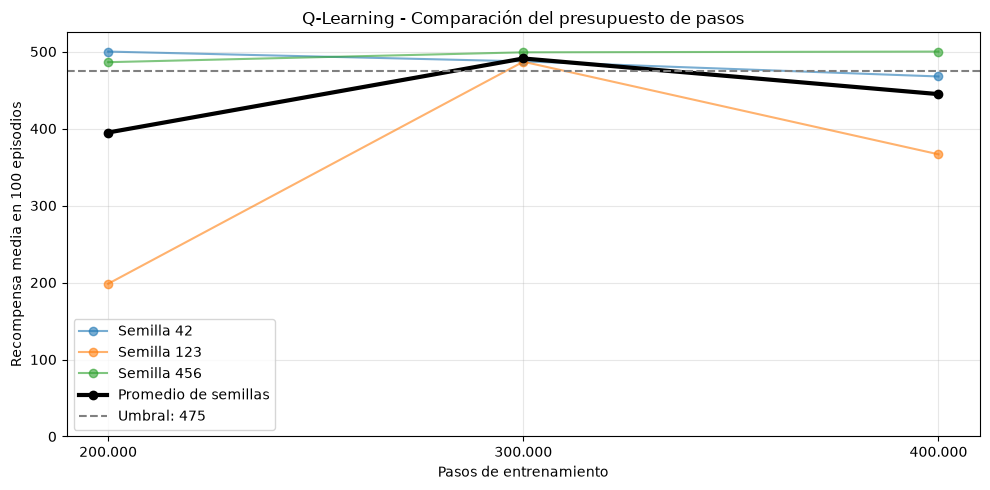


RECOMPENSA MEDIA EN 100 EPISODIOS
Pasos       Semilla 42    Semilla 123   Semilla 456   
200000      500.00        198.38        486.23        
300000      487.28        486.84        499.04        
400000      467.67        366.55        500.00        

RESUMEN POR PRESUPUESTO
Pasos       Promedio      Desviación     Semillas >= 475
200000      394.87        139.05         2/3
300000      491.05        5.65           3/3
400000      444.74        56.84          1/3


In [35]:

# ============================================================
# PART 14 - GRÁFICA Y RESULTADOS DEL ENTRENAMIENTO
# ============================================================

# Puntos donde evaluamos el rendimiento del agente
puntos = [200_000, 300_000, 400_000]

# Crear la gráfica comparativa
plt.figure(figsize=(10, 5))

# Mostrar el rendimiento de cada semilla
for seed in SEMILLAS:

    # Seleccionar y ordenar las evaluaciones de esta semilla
    datos = sorted(
        [
            fila for fila in resultados_presupuesto
            if fila["seed"] == seed
        ],
        key=lambda fila: fila["steps"]
    )

    # Obtener los pasos y las recompensas
    pasos_semilla = [fila["steps"] for fila in datos]
    recompensas = [fila["mean_reward"] for fila in datos]

    # Dibujar la curva correspondiente a esta semilla
    plt.plot(
        pasos_semilla,
        recompensas,
        marker="o",
        alpha=0.6,
        label=f"Semilla {seed}"
    )

# Calcular los promedios y las desviaciones entre semillas
medias = []
desviaciones = []

for paso in puntos:

    # Obtener las recompensas de las tres semillas
    valores = np.array([
        fila["mean_reward"]
        for fila in resultados_presupuesto
        if fila["steps"] == paso
    ])

    medias.append(np.mean(valores))
    desviaciones.append(np.std(valores))

# Dibujar el promedio de las tres semillas
plt.plot(
    puntos,
    medias,
    marker="o",
    linewidth=3,
    color="black",
    label="Promedio de semillas"
)

# Mostrar el umbral de rendimiento de CartPole
plt.axhline(
    y=475,
    color="gray",
    linestyle="--",
    label="Umbral: 475"
)

# Configurar la presentación de la gráfica
plt.title("Q-Learning - Comparación del presupuesto de pasos")
plt.xlabel("Pasos de entrenamiento")
plt.ylabel("Recompensa media en 100 episodios")
plt.xticks(
    puntos,
    ["200.000", "300.000", "400.000"]
)
plt.ylim(0, 525)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Mostrar la gráfica directamente en el notebook
plt.show()


# ============================================================
# TABLA DE RECOMPENSAS POR SEMILLA
# ============================================================

print("\nRECOMPENSA MEDIA EN 100 EPISODIOS")

print(
    f"{'Pasos':<12}"
    f"{'Semilla 42':<14}"
    f"{'Semilla 123':<14}"
    f"{'Semilla 456':<14}"
)

for paso in puntos:

    # Obtener la recompensa correspondiente a cada semilla
    valores = [
        next(
            fila["mean_reward"]
            for fila in resultados_presupuesto
            if fila["steps"] == paso and fila["seed"] == seed
        )
        for seed in SEMILLAS
    ]

    # Mostrar los resultados de cada evaluación
    print(
        f"{paso:<12}"
        f"{valores[0]:<14.2f}"
        f"{valores[1]:<14.2f}"
        f"{valores[2]:<14.2f}"
    )


# ============================================================
# RESUMEN GENERAL POR PRESUPUESTO
# ============================================================

print("\nRESUMEN POR PRESUPUESTO")

print(
    f"{'Pasos':<12}"
    f"{'Promedio':<14}"
    f"{'Desviación':<15}"
    f"{'Semillas >= 475'}"
)

for paso in puntos:

    # Obtener los resultados de las tres semillas
    recompensas = np.array([
        fila["mean_reward"]
        for fila in resultados_presupuesto
        if fila["steps"] == paso
    ])

    # Calcular promedio, desviación y semillas exitosas
    promedio = np.mean(recompensas)
    desviacion = np.std(recompensas)
    exitosas = np.sum(recompensas >= 475)

    print(
        f"{paso:<12}"
        f"{promedio:<14.2f}"
        f"{desviacion:<15.2f}"
        f"{exitosas}/3"
    )


### Part 15 - Final Validation

In [ ]:

# ============================================================
# PART 15 - VALIDACIÓN FINAL DE Q-LEARNING
# ============================================================

# Semillas nuevas que no utilizamos para ajustar los parámetros
semillas_validacion = [7, 21, 99]

# Conservar los límites actuales
minimos_anteriores = MINIMOS.copy()
maximos_anteriores = MAXIMOS.copy()

resultados_validacion = []

try:
    # Utilizar los límites del Ajuste A
    MINIMOS = np.array([-2.4, -2.0, -0.2095, -2.5])
    MAXIMOS = np.array([2.4, 2.0, 0.2095, 2.5])

    for seed in semillas_validacion:

        # Entrenar un agente nuevo durante 300.000 pasos
        Q_validacion, historial, resumen = entrenar_epsilon_decay(
            seed=seed,
            n_bins=10,
            total_steps=300_000,
            eval_interval=10_000,
            alpha=0.1
        )

        # Conservar las estadísticas de evaluación
        resultados_validacion.append(resumen)

        print(
            f"Semilla: {seed} | "
            f"Recompensa: {resumen['final_mean']:.2f} | "
            f"Desviación: {resumen['final_std']:.2f} | "
            f"Tiempo: {resumen['time_seconds']:.2f} s"
        )

finally:
    # Restaurar los límites anteriores
    MINIMOS = minimos_anteriores.copy()
    MAXIMOS = maximos_anteriores.copy()


# ============================================================
# RESULTADOS DE VALIDACIÓN
# ============================================================

recompensas = np.array([
    fila["final_mean"]
    for fila in resultados_validacion
])

print("\nVALIDACIÓN FINAL")
print(f"Recompensa promedio: {np.mean(recompensas):.2f}")
print(f"Desviación entre semillas: {np.std(recompensas):.2f}")zaaaaa
print(f"Semillas con recompensa >= 475: {np.sum(recompensas >= 475)}/3")


Semilla: 7 | Recompensa: 500.00 | Desviación: 0.00 | Tiempo: 65.67 s
Semilla: 21 | Recompensa: 474.45 | Desviación: 55.04 | Tiempo: 47.92 s
Semilla: 99 | Recompensa: 486.15 | Desviación: 48.29 | Tiempo: 44.83 s

VALIDACIÓN FINAL
Recompensa promedio: 486.87
Desviación entre semillas: 10.44
Semillas con recompensa >= 475: 2/3


### Part 16 - Final Results and Conclusions


DISCRETIZACIONES - 200.000 PASOS
Intervalos | Media | Desviación
-----------------------------------------------------------------
6 | 196.28 | 69.63
10 | 218.05 | 108.85
20 | 145.93 | 50.94

ALPHA - 10 INTERVALOS Y EPSILON DECRECIENTE
Alpha | Media | Desviación
-----------------------------------------------------------------
0.1 | 297.10 | 133.29
0.3 | 274.40 | 63.02
0.5 | 212.68 | 22.65

LÍMITES DE DISCRETIZACIÓN - 200.000 PASOS
Configuración | Media | Desviación
-----------------------------------------------------------------
Original | 297.10 | 133.29
Ajuste A | 394.87 | 139.05
Ajuste B | 354.88 | 97.03

PRESUPUESTO DE ENTRENAMIENTO - AJUSTE A
Pasos | Media | Desviación | Semillas >= 475
-----------------------------------------------------------------
200000 | 394.87 | 139.05 | 2/3
300000 | 491.05 | 5.65 | 3/3
400000 | 444.74 | 56.84 | 1/3

VALIDACIÓN FINAL - 300.000 PASOS
Semilla | Media | Desviación
-----------------------------------------------------------------
7 | 500.00 

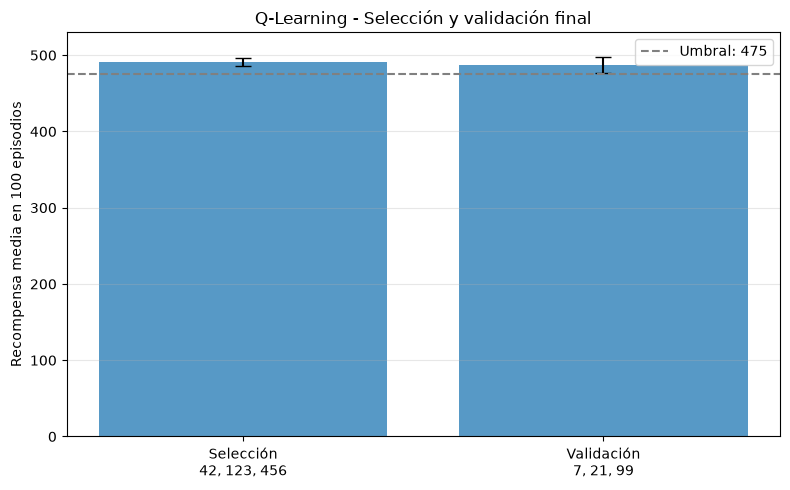

In [38]:

# ============================================================
# PART 16 - RESULTADOS FINALES DE Q-LEARNING
# ============================================================

# Mostrar una tabla sin utilizar pandas
def mostrar_tabla(titulo, encabezados, filas):
    print(f"\n{titulo}")
    print(" | ".join(encabezados))
    print("-" * 65)

    for fila in filas:
        print(" | ".join(str(valor) for valor in fila))


# ============================================================
# 1. COMPARACIÓN DE DISCRETIZACIONES
# ============================================================

filas_bins = []

for n_bins in [6, 10, 20]:

    datos = [
        fila for fila in todos_resumenes
        if fila["bins"] == n_bins
    ]

    recompensas = np.array([
        fila["final_mean"] for fila in datos
    ])

    filas_bins.append([
        n_bins,
        f"{np.mean(recompensas):.2f}",
        f"{np.std(recompensas):.2f}"
    ])

mostrar_tabla(
    "DISCRETIZACIONES - 200.000 PASOS",
    ["Intervalos", "Media", "Desviación"],
    filas_bins
)


# ============================================================
# 2. COMPARACIÓN DE ALPHA
# ============================================================

filas_alpha = []

for alpha in [0.1, 0.3, 0.5]:

    recompensas = np.array([
        fila["final_mean"]
        for fila in resultados_alpha[alpha]
    ])

    filas_alpha.append([
        alpha,
        f"{np.mean(recompensas):.2f}",
        f"{np.std(recompensas):.2f}"
    ])

mostrar_tabla(
    "ALPHA - 10 INTERVALOS Y EPSILON DECRECIENTE",
    ["Alpha", "Media", "Desviación"],
    filas_alpha
)


# ============================================================
# 3. COMPARACIÓN DE LÍMITES
# ============================================================

filas_limites = []

for nombre, datos in resultados_limites.items():

    recompensas = np.array([
        fila["final_mean"] for fila in datos
    ])

    filas_limites.append([
        nombre,
        f"{np.mean(recompensas):.2f}",
        f"{np.std(recompensas):.2f}"
    ])

mostrar_tabla(
    "LÍMITES DE DISCRETIZACIÓN - 200.000 PASOS",
    ["Configuración", "Media", "Desviación"],
    filas_limites
)


# ============================================================
# 4. COMPARACIÓN DE PRESUPUESTO DE PASOS
# ============================================================

filas_presupuesto = []

for paso in [200_000, 300_000, 400_000]:

    recompensas = np.array([
        fila["mean_reward"]
        for fila in resultados_presupuesto
        if fila["steps"] == paso
    ])

    filas_presupuesto.append([
        paso,
        f"{np.mean(recompensas):.2f}",
        f"{np.std(recompensas):.2f}",
        f"{np.sum(recompensas >= 475)}/3"
    ])

mostrar_tabla(
    "PRESUPUESTO DE ENTRENAMIENTO - AJUSTE A",
    ["Pasos", "Media", "Desviación", "Semillas >= 475"],
    filas_presupuesto
)


# ============================================================
# 5. VALIDACIÓN CON SEMILLAS NUEVAS
# ============================================================

recompensas_validacion = np.array([
    fila["final_mean"]
    for fila in resultados_validacion
])

filas_validacion = [
    [fila["seed"], f"{fila['final_mean']:.2f}",
     f"{fila['final_std']:.2f}"]
    for fila in resultados_validacion
]

mostrar_tabla(
    "VALIDACIÓN FINAL - 300.000 PASOS",
    ["Semilla", "Media", "Desviación"],
    filas_validacion
)

print(f"\nMedia de validación: {np.mean(recompensas_validacion):.2f}")
print(f"Desviación entre semillas: {np.std(recompensas_validacion):.2f}")
print(f"Semillas >= 475: {np.sum(recompensas_validacion >= 475)}/3")


# ============================================================
# 6. GRÁFICA DE LA CONFIGURACIÓN SELECCIONADA
# ============================================================

# Recuperar las recompensas a los 300.000 pasos
recompensas_seleccion = np.array([
    fila["mean_reward"]
    for fila in resultados_presupuesto
    if fila["steps"] == 300_000
])

grupos = [
    "Selección\n42, 123, 456",
    "Validación\n7, 21, 99"
]

medias = [
    np.mean(recompensas_seleccion),
    np.mean(recompensas_validacion)
]

desviaciones = [
    np.std(recompensas_seleccion),
    np.std(recompensas_validacion)
]

plt.figure(figsize=(8, 5))

# Mostrar promedios con la variación entre semillas
plt.bar(
    grupos,
    medias,
    yerr=desviaciones,
    capsize=6,
    alpha=0.75
)

# Indicar el objetivo del proyecto
plt.axhline(
    475,
    color="gray",
    linestyle="--",
    label="Umbral: 475"
)

plt.title("Q-Learning - Selección y validación final")
plt.ylabel("Recompensa media en 100 episodios")
plt.ylim(0, 530)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Mostrar únicamente en el notebook
plt.show()
